# 01 · Análisis exploratorio de datos (CRISP-DM fase 2)

**Objetivo:** entender el dataset *Fruit Quality Classification* (FruitNet) antes de modelar: distribución de clases, desbalance, calidad y variabilidad de las imágenes, y posibles sesgos.

Requisitos previos: `python -m src.data.download`, `python -m src.data.manifest`, `python -m src.data.split`, `python -m src.data.preprocess` y `python -m src.features.handcrafted`.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from src.utils.paths import MANIFEST_PATH, SPLITS_PATH, RAW_DATASET, RESULTS
from src.utils import plotting
from src.evaluation.metrics import FRUITS, FRUIT_ES
from src.data.preprocess import load_split
from src.features.handcrafted import features_path, feature_names
plotting.setup()
man = pd.read_csv(MANIFEST_PATH)
splits = pd.read_csv(SPLITS_PATH)
print(f"Imágenes en el dataset: {len(man):,}")

Imágenes en el dataset: 19,526


## 1. Distribución de clases y copias aumentadas

El dataset trae 6 frutas × {buena, mala}, más una carpeta *Mixed* con varias frutas por foto. Varias imágenes son **copias aumentadas** de una misma foto (mismo timestamp con sufijo, p. ej. `20190820_143522_22896.jpg`). Se compara el número de archivos con el número de fotos originales (capturas).

In [2]:
tab = (man.groupby(["fruit", "quality"])
         .agg(archivos=("path", "size"), capturas=("capture", "nunique"), rafagas=("group", "nunique"))
         .reset_index())
tab["copias_%"] = (100 * (1 - tab.capturas / tab.archivos)).round(1)
tab

,fruit,quality,archivos,capturas,rafagas,copias_%
0,apple,bad,1141,799,56,30.0
1,apple,good,1149,1132,178,1.5
2,apple,mixed,113,107,8,5.3
3,banana,bad,1087,794,94,27.0
4,banana,good,1113,1092,209,1.9
5,banana,mixed,285,208,12,27.0
6,guava,bad,1129,763,31,32.4
7,guava,good,1152,1124,200,2.4
8,guava,mixed,148,120,10,18.9
9,lime,bad,1085,943,140,13.1


Razón de desbalance (máx/mín): archivos 5.47 -> originales 1.51


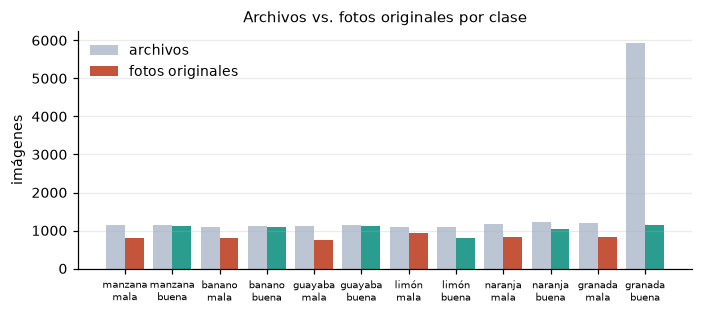

In [3]:
lab = tab[tab.quality != "mixed"].copy()
lab["clase"] = lab.fruit.map(FRUIT_ES) + "\n" + lab.quality.map({"good": "buena", "bad": "mala"})
fig, ax = plt.subplots(figsize=(7.2, 2.8))
x = np.arange(len(lab))
ax.bar(x - 0.2, lab.archivos, 0.4, label="archivos", color="#bcc5d3")
ax.bar(x + 0.2, lab.capturas, 0.4, label="fotos originales",
       color=[plotting.QUALITY_COLORS[q] for q in lab.quality])
ax.set_xticks(x, lab.clase, fontsize=6.5)
ax.grid(axis="x", visible=False)
ax.set_ylabel("imágenes")
ax.set_title("Archivos vs. fotos originales por clase")
ax.legend(frameon=False)
plotting.save(fig, "eda_distribucion_clases")
ratio = lab.archivos.max() / lab.archivos.min(), lab.capturas.max() / lab.capturas.min()
print(f"Razón de desbalance (máx/mín): archivos {ratio[0]:.2f} -> originales {ratio[1]:.2f}")

**Hallazgo.** La clase *granada buena* tiene 5.940 archivos, pero solo 1.154 fotos originales: el 81 % son copias aumentadas. Al conservar solo una imagen por captura, el desbalance máximo baja de ≈5,5:1 a ≈1,5:1, y se elimina una fuente de **fuga de información**: una copia en entrenamiento y otra en prueba harían que el modelo "vea el examen".

## 2. Resolución y formato de las imágenes

In [4]:
sample = man.groupby("folder").sample(60, random_state=0)
sizes = sample.path.map(lambda p: Image.open(RAW_DATASET / p).size)
sample = sample.assign(res=sizes.map(lambda s: f"{s[0]}×{s[1]}"))
pd.crosstab(sample.res, sample.quality)

quality,bad,good,mixed
res,,,
144×256,1,0,0
192×256,141,55,155
256×192,21,48,205
256×256,197,252,0
3000×4000,0,4,0
8000×6000,0,1,0


La mayoría de las imágenes son de 256×256 o 256×192 (vertical u horizontal), con unas pocas fotos originales de 3000×4000. Para homogeneizar, se recorta el **cuadrado central** y se redimensiona a 128×128 (`src/data/preprocess.py`), lo que conserva la proporción de la fruta.

## 3. Ejemplos por clase

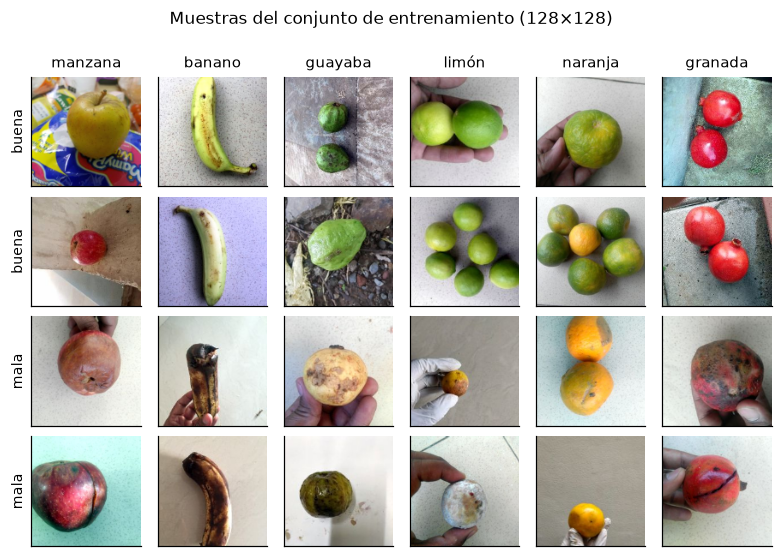

In [5]:
Xtr, mtr = load_split("train", splits)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 6, figsize=(7.2, 5.0))
for j, fruit in enumerate(FRUITS):
    for i, q in enumerate(["good", "good", "bad", "bad"]):
        idx = rng.choice(np.where((mtr.fruit == fruit) & (mtr.quality == q))[0])
        ax = axes[i, j]; ax.imshow(Xtr[idx]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if i == 0: ax.set_title(FRUIT_ES[fruit])
        if j == 0: ax.set_ylabel("buena" if q == "good" else "mala")
fig.suptitle("Muestras del conjunto de entrenamiento (128×128)", y=1.0)
fig.tight_layout()
plotting.save(fig, "eda_muestras")

**Variabilidad observada:** hay fotos con una o varias frutas, manos y guantes en la escena, y fondos de pasto, baldosa, tela o pared con iluminación variable. Esto se aleja del supuesto del enunciado (una fruta sobre fondo uniforme) y anticipa un reto de **generalización**.

## 4. Imagen promedio por clase

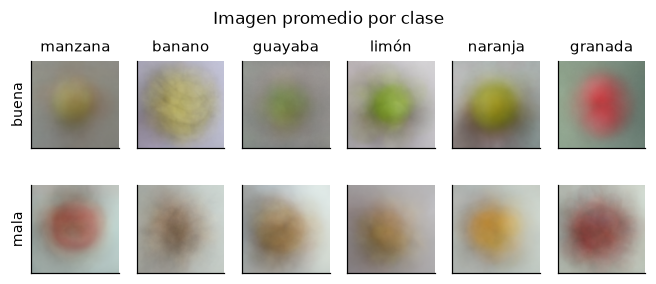

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(7.2, 2.7))
for j, fruit in enumerate(FRUITS):
    for i, q in enumerate(["good", "bad"]):
        m = Xtr[(mtr.fruit == fruit) & (mtr.quality == q)].mean(0).astype(np.uint8)
        ax = axes[i, j]; ax.imshow(m); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if i == 0: ax.set_title(FRUIT_ES[fruit])
        if j == 0: ax.set_ylabel("buena" if q == "good" else "mala")
fig.suptitle("Imagen promedio por clase", y=1.02)
plotting.save(fig, "eda_imagen_promedio")

Las imágenes promedio de las frutas malas son más oscuras y marrones (podredumbre). También se ven **diferencias sistemáticas de fondo** entre las clases buena y mala de una misma fruta (por ejemplo, la guayaba), lo que sugiere un posible sesgo de captura.

## 5. Color y defectos: ¿qué separa una fruta buena de una mala?

Se comparan dos indicadores de defectos de `src/features/handcrafted.py`: la fracción de píxeles oscuros (V < 60) y la fracción de píxeles marrones (H ∈ [5°, 25°]·2, S > 80, V < 150).

dark         brown           val       
calidad  buena   mala  buena   mala  buena   mala
fruta                                            
banano   0.032  0.043  0.058  0.101  0.712  0.707
granada  0.032  0.035  0.010  0.065  0.621  0.637
guayaba  0.038  0.023  0.008  0.102  0.600  0.711
limón    0.041  0.039  0.018  0.113  0.682  0.617
manzana  0.043  0.023  0.062  0.058  0.601  0.722
naranja  0.054  0.012  0.057  0.042  0.619  0.781

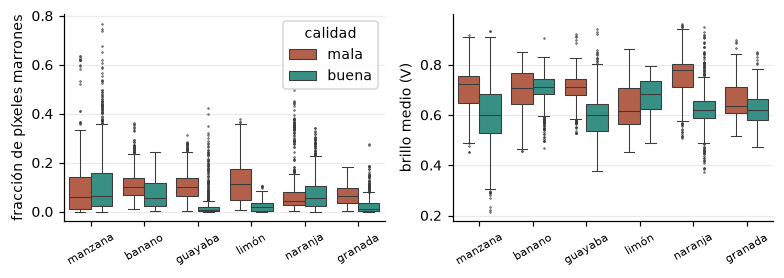

In [7]:
F = np.load(features_path("train", "full"))["X"]
names = feature_names()
df = mtr.assign(dark=F[:, names.index("dark_ratio")], brown=F[:, names.index("brown_ratio")],
                sat=F[:, names.index("hsv_mean_1")], val=F[:, names.index("hsv_mean_2")])
df["fruta"] = df.fruit.map(FRUIT_ES); df["calidad"] = df.quality.map({"good": "buena", "bad": "mala"})
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=False)
pal = {"buena": plotting.QUALITY_COLORS["good"], "mala": plotting.QUALITY_COLORS["bad"]}
sns.boxplot(df, x="fruta", y="brown", hue="calidad", ax=axes[0], palette=pal, fliersize=0.5, linewidth=0.7)
sns.boxplot(df, x="fruta", y="val", hue="calidad", ax=axes[1], palette=pal, fliersize=0.5, linewidth=0.7)
axes[0].set_ylabel("fracción de píxeles marrones"); axes[1].set_ylabel("brillo medio (V)")
for a in axes: a.tick_params(axis="x", labelsize=7, rotation=30); a.set_xlabel("")
axes[1].legend_.remove()
fig.tight_layout()
plotting.save(fig, "eda_color_calidad")
df.groupby(["fruta", "calidad"])[["dark", "brown", "val"]].median().round(3).unstack()

**Lectura cuidadosa de la tabla:**

- La **fracción marrón** es claramente mayor en las frutas malas de banano, granada, guayaba y limón (podredumbre, manchas), pero **no** en manzana ni naranja, donde el color natural de la fruta sana ya cae en ese rango de tono.
- El **brillo medio** es *mayor* en las frutas malas de manzana, guayaba y naranja. No es un efecto del defecto (una zona podrida es más oscura), sino del **fondo**: muchas fotos de frutas malas se tomaron sobre superficies grises claras (ver sección 6).

Conclusión: ningún indicador de color por sí solo separa las clases en todas las frutas. Esto justifica combinar **color + textura (LBP, GLCM) + forma (HOG)** y aprender reglas distintas por fruta (modelo conjunto de 12 clases).

## 6. Sesgo de fondo

**Pregunta:** ¿el fondo de la foto delata la clase? Para medirlo, se entrenaron modelos que **solo ven una franja de 16 px del borde** de la imagen (casi siempre fondo) con `python -m src.training.train_ml --models logreg rf --features background`.

In [8]:
rows = []
for tag in ["logreg_background", "rf_background", "logreg"]:
    p = RESULTS / f"metrics_{tag}.json"
    if p.exists():
        m = json.loads(p.read_text())
        rows.append({"modelo": tag, "acc. calidad (val)": m["val"]["quality_accuracy"],
                     "F1-macro 12 clases (val)": m["val"]["joint_f1_macro"],
                     "acc. fruta (val)": m["val"]["fruit_accuracy"]})
pd.DataFrame(rows).round(3)

,modelo,acc. calidad (val),F1-macro 12 clases (val),acc. fruta (val)
0,logreg_background,0.821,0.570,0.622
1,rf_background,0.854,0.712,0.749
2,logreg,0.935,0.842,0.874


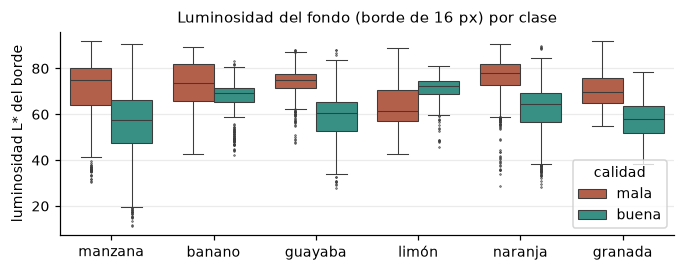

In [9]:
B = np.load(features_path("train", "background"))["X"]
bg = mtr.assign(L=B[:, 43] * 100)  # columna 43 = media de L* (Lab), reescalada a 0-100
bg["fruta"] = bg.fruit.map(FRUIT_ES); bg["calidad"] = bg.quality.map({"good": "buena", "bad": "mala"})
fig, ax = plt.subplots(figsize=(7.2, 2.4))
sns.boxplot(bg, x="fruta", y="L", hue="calidad", palette=pal, ax=ax, fliersize=0.5, linewidth=0.7)
ax.set_ylabel("luminosidad L* del borde"); ax.set_xlabel(""); ax.set_title("Luminosidad del fondo (borde de 16 px) por clase")
plotting.save(fig, "eda_sesgo_fondo")

**Hallazgo crítico.** Un Random Forest que solo ve el borde de la imagen acierta la calidad en ~85 % de las fotos de validación (el azar sería ~50 %). Las fotos de cada clase se tomaron en sesiones y escenarios distintos, así que **el fondo está correlacionado con la etiqueta**. Consecuencias:

1. Las métricas sobre el conjunto de prueba de Kaggle son una **cota optimista**: parte del acierto puede venir del fondo.
2. Se necesita una evaluación externa con fondos controlados: las **fotos propias del grupo** (`data/own/`) y la carpeta *Mixed*.
3. Mitigaciones adoptadas: recorte central (reduce el área de fondo), aumento de datos con recortes y rotaciones en la CNN, y análisis Grad-CAM para verificar dónde mira la red.

Este hallazgo también tiene una dimensión **ética**: un sistema que aprende atajos espurios puede fallar sistemáticamente en contextos distintos (otro mercado, otra iluminación) y perjudicar a productores cuyas frutas se fotografían en condiciones diferentes.

## 7. Partición de los datos

In [10]:
t = pd.crosstab(splits.label, splits.split)
t.loc["TOTAL"] = t.sum()
leak = splits[splits.split != "mixed"].groupby("group").split.nunique().gt(1).sum()
print(f"Grupos (ráfagas) repartidos entre conjuntos: {leak}")
t

Grupos (ráfagas) repartidos entre conjuntos: 0


split,mixed,test,train,val
label,,,,
apple_bad,0,115,570,114
apple_good,0,162,809,161
apple_mixed,107,0,0,0
banana_bad,0,113,568,113
banana_good,0,156,780,156
banana_mixed,208,0,0,0
guava_bad,0,107,541,115
guava_good,0,161,803,160
guava_mixed,120,0,0,0


La partición es **estratificada** (misma proporción de las 12 clases en cada conjunto) y **agrupada por ráfaga**: todas las fotos de una misma fruta tomadas en el mismo minuto quedan en un solo conjunto. Proporciones ≈ 72 % / 14 % / 14 %.

## 8. Conclusiones del EDA

| Aspecto | Hallazgo | Decisión |
|---|---|---|
| Copias aumentadas | 39 % de las imágenes etiquetadas son copias (81 % en granada buena) | Una imagen por captura |
| Desbalance | 5,5:1 → 1,5:1 tras deduplicar | Pesos de clase w_k = N/(K·N_k) |
| Ráfagas | Varias vistas de la misma fruta en segundos | Partición agrupada (StratifiedGroupKFold) |
| Resolución | 256×256 / 256×192 / 3000×4000 | Recorte central + 128×128 |
| Variabilidad | Manos, varias frutas, fondos diversos | Aumento de datos; evaluación externa |
| Sesgo de fondo | El borde predice la calidad con ~85 % | Reportar como limitación; Grad-CAM; fotos propias |
| Señal de calidad | Color marrón/oscuro + textura | Características HSV/Lab + LBP/GLCM + HOG |